In [41]:
import pandas as pd

Teen_Mental_Health_Dataset = pd.read_csv('../data/Teen_Mental_Health_Dataset.csv');

print("head:")
display(Teen_Mental_Health_Dataset.head())

print("info:")
display(Teen_Mental_Health_Dataset.info())

print("describe:")
display(Teen_Mental_Health_Dataset.describe())

print("null values:")
display(Teen_Mental_Health_Dataset.isnull().sum())

print("duplicated values:")
display(Teen_Mental_Health_Dataset.duplicated().sum())

print("unique values:")
display(Teen_Mental_Health_Dataset.nunique())

target = 'depression_label'

head:


,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0


info:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       1200 non-null   int64  
 1   gender                    1200 non-null   str    
 2   daily_social_media_hours  1200 non-null   float64
 3   platform_usage            1200 non-null   str    
 4   sleep_hours               1200 non-null   float64
 5   screen_time_before_sleep  1200 non-null   float64
 6   academic_performance      1200 non-null   float64
 7   physical_activity         1200 non-null   float64
 8   social_interaction_level  1200 non-null   str    
 9   stress_level              1200 non-null   int64  
 10  anxiety_level             1200 non-null   int64  
 11  addiction_level           1200 non-null   int64  
 12  depression_label          1200 non-null   int64  
dtypes: float64(5), int64(5), str(3)
memory usage: 122.0 KB


None

describe:


...

age                         0
gender                      0
daily_social_media_hours    0
platform_usage              0
sleep_hours                 0
screen_time_before_sleep    0
academic_performance        0
physical_activity           0
social_interaction_level    0
stress_level                0
anxiety_level               0
addiction_level             0
depression_label            0
dtype: int64

duplicated values:


np.int64(0)

unique values:


age                           7
gender                        2
daily_social_media_hours     71
platform_usage                3
sleep_hours                  51
screen_time_before_sleep     26
academic_performance        201
physical_activity            21
social_interaction_level      3
stress_level                 10
anxiety_level                10
addiction_level              10
depression_label              2
dtype: int64

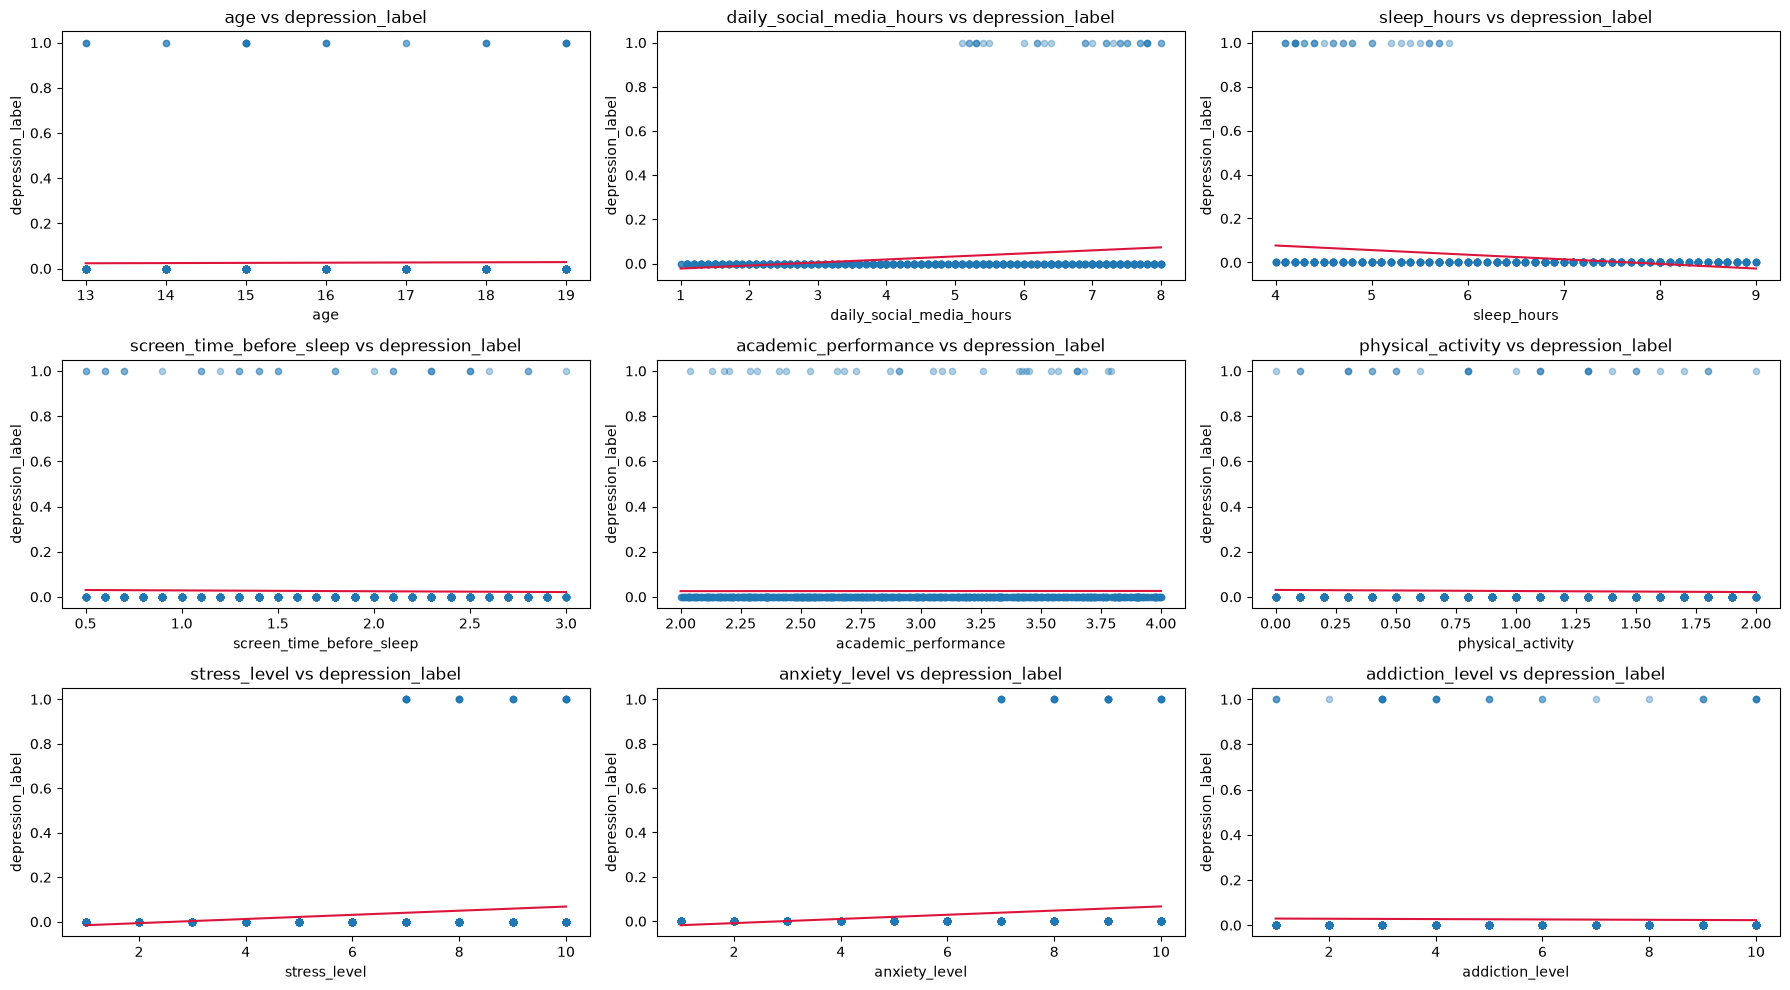

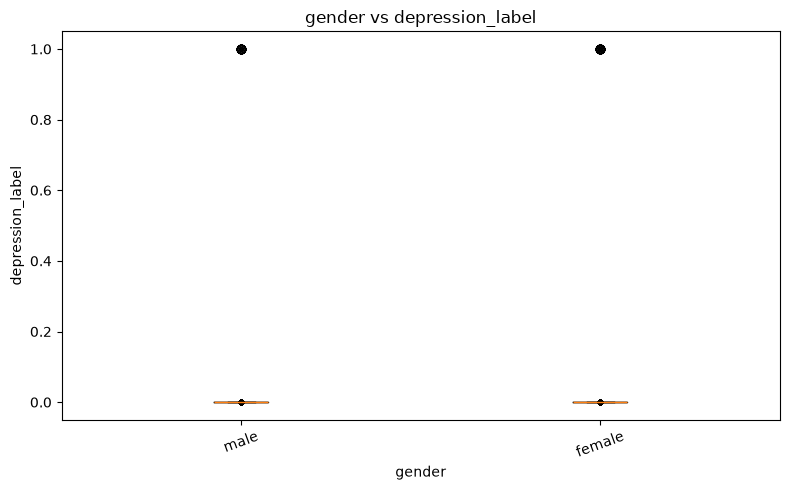

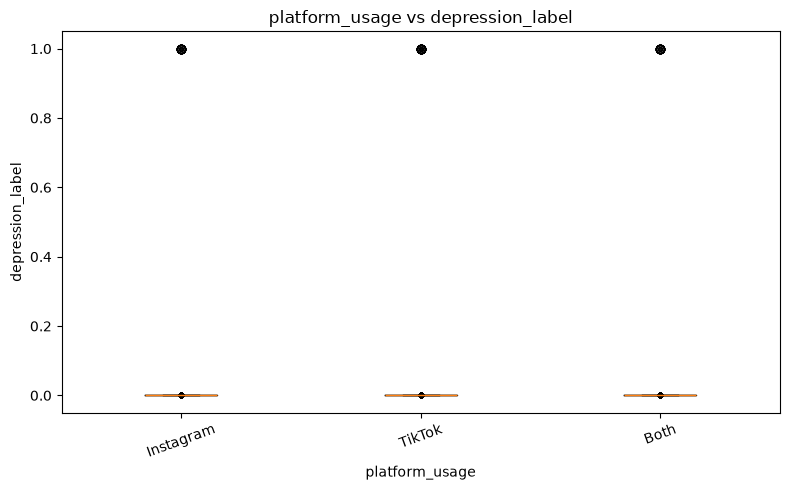

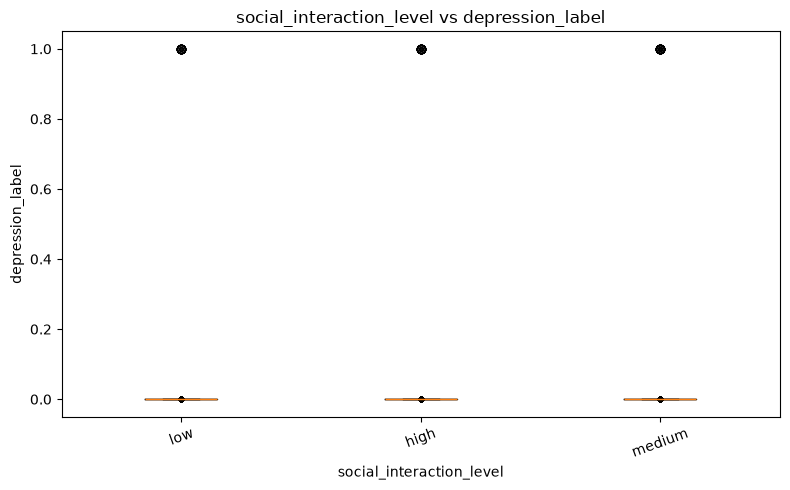

In [42]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = Teen_Mental_Health_Dataset.copy()
numeric_features = plot_data.select_dtypes(exclude=['object', 'str']).columns.drop(target)
categorical_features = plot_data.select_dtypes(include=['object', 'str']).columns

fig, axes = plt.subplots(3, 3, figsize=(18, 10))
for ax, feature in zip(axes.flat, numeric_features):
    ax.scatter(plot_data[feature], plot_data[target], alpha=0.35, s=20)
    coefficients = plot_data[[feature, target]].dropna().pipe(lambda frame: np.polyfit(frame[feature], frame[target], 1))
    line = plot_data[feature].sort_values()
    ax.plot(line, coefficients[0] * line + coefficients[1], color='crimson')
    ax.set_title(f'{feature} vs {target}')
    ax.set_xlabel(feature)
    ax.set_ylabel(target)

for ax in axes.flat[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

for feature in categorical_features:
    plt.figure(figsize=(8, 5))
    categories = plot_data[feature].dropna().unique()
    values = [plot_data.loc[plot_data[feature] == category, target] for category in categories]
    plt.boxplot(values, tick_labels=categories)
    for index, category_values in enumerate(values, start=1):
        x_values = [index] * len(category_values)
        plt.scatter(x_values, category_values, color='black', alpha=0.25, s=10)
    plt.title(f'{feature} vs {target}')
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


In [43]:
data = Teen_Mental_Health_Dataset.copy()

X = data.drop(columns=[target])
y = data[target]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Class distribution:')
display(y_train.value_counts())
display(X_train.describe())

Class distribution:


depression_label
0    935
1     25
Name: count, dtype: int64

,age,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,stress_level,anxiety_level,addiction_level
count,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000
mean,15.912500,4.570417,6.448125,1.749792,2.995292,1.018438,5.436458,5.655208,5.572917
std,2.022978,2.049965,1.464461,0.715536,0.574654,0.582937,2.885027,2.870306,2.805643
min,13.000000,1.000000,4.000000,0.500000,2.000000,0.000000,1.000000,1.000000,1.000000
25%,14.000000,2.700000,5.100000,1.100000,2.510000,0.500000,3.000000,3.000000,3.000000
50%,16.000000,4.600000,6.500000,1.800000,2.990000,1.000000,5.000000,6.000000,6.000000
75%,18.000000,6.400000,7.700000,2.400000,3.482500,1.500000,8.000000,8.000000,8.000000
max,19.000000,8.000000,9.000000,3.000000,4.000000,2.000000,10.000000,10.000000,10.000000


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

categorical_features = X.select_dtypes(include=["str"]).columns
numerical_features = X.select_dtypes(exclude=["str"]).columns

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features,
        ),
    ]
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="f1_macro",
)

print(f"Macro-F1 scores: {scores}")
print(f"Mean macro-F1: {scores.mean():.3f}")
print(f"95% range: +/- {scores.std() * 2:.3f}")

Macro-F1 scores: [0.66137566 0.82933333 0.66137566 0.78173551 0.8973262 ]
Mean macro-F1: 0.766
95% range: +/- 0.186


In [45]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score

model = pipeline.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Balanced accuracy:", balanced_accuracy_score(y_test, predictions))
print("Macro-F1:", f1_score(y_test, predictions, average="macro"))
print("\nClassification report:\n")
print(classification_report(y_test, predictions, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, predictions, labels=model.classes_), index=model.classes_, columns=model.classes_))

Accuracy: 0.9875
Balanced accuracy: 0.75
Macro-F1: 0.8301486199575372

Classification report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       234
           1       1.00      0.50      0.67         6

    accuracy                           0.99       240
   macro avg       0.99      0.75      0.83       240
weighted avg       0.99      0.99      0.99       240



,0,1
0,234,0
1,3,3
